In [51]:
from qutip import coherent, fock, destroy, num, qeye, Qobj
from qutip.visualization import plot_fock_distribution

In [203]:
from matplotlib import pyplot as plt
import numpy as np
import math
from math import comb

### 0. Cat Code Fidelity

In [9]:
def avrg_fidelity(alpha, kt=0.001):
    b = alpha**2
    A = 1 - 0.5*kt*b*(np.sinh(b)-np.sin(b))/(np.cosh(b)+np.cos(b))
    B = 1 - 0.5*kt*b*(np.sinh(b)+np.sin(b))/(np.cosh(b)-np.cos(b))
    r = A/B
    return (r**4 + 4*r**3 - 4*r - 1 + 4*np.log(r)*r**2)/(2*(r-1)*(r+1)**3)

In [10]:
def plot_fidelities(kt=0.02):
    alpha_range = np.linspace(1, 3, 100)
    fideliies = avrg_fidelity(alpha_range, kt)
    plt.plot(alpha_range, fideliies)
    plt.title(f"Avarage Fidelity of Recovered state 4-legged cat code kt={kt}")
    plt.xlabel("alpha")
    plt.ylabel("fidelity")
    plt.show()

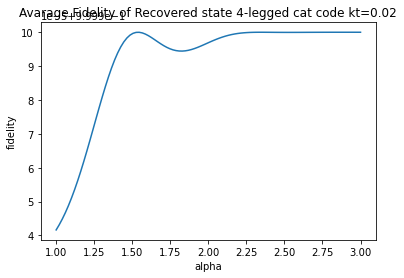

In [11]:
plot_fidelities()

### 1. Building Logical States

In [12]:
def two_legged_cat(N_max, alpha):
    assert alpha >= 1 and alpha <= 3, "alpha needs to be in interval [1,3]"
    a0 = coherent(N_max, alpha)
    a1 = coherent(N_max, -alpha)
    logical0 = (a0 + a1).unit()
    logical1 = (a0 - a1).unit()
    return logical0, logical1

In [13]:
def four_legged_cat(N_max, alpha):
    assert alpha >= 1 and alpha <= 3, "alpha needs to be in interval [1,3]"
    a0 = coherent(N_max, alpha)
    a1 = coherent(N_max, 1j*alpha)
    a2 = coherent(N_max, -alpha)
    a3 = coherent(N_max, -1j*alpha)
    logical0 = (a0 + a1 + a2 + a3).unit()
    logical1 = (a0 - a1 + a2 - a3).unit()
    return logical0, logical1

In [14]:
def binomial_ND_22(N_max):
    logical0 = np.sqrt(1/2)*(fock(N_max, 0) + fock(N_max, 4))
    logical1 = fock(N_max, 2)
    return logical0, logical1

In [15]:
def binomial_ND_024(N_max):
    logical0 = 0.5*fock(N_max, 0) + np.sqrt(3/4)*fock(N_max, 4)
    logical1 = np.sqrt(3/4)*fock(N_max, 2) + 0.5*fock(N_max, 6)
    return logical0, logical1

In [79]:
def binomial_ND_31(N_max):
    logical0 = np.sqrt(1/2)*(fock(N_max, 0) + fock(N_max,6))
    logical1 = fock(N_max, 3)
    return logical0, logical1

(<Figure size 576x432 with 1 Axes>,
 <AxesSubplot:xlabel='Fock number', ylabel='Occupation probability'>)

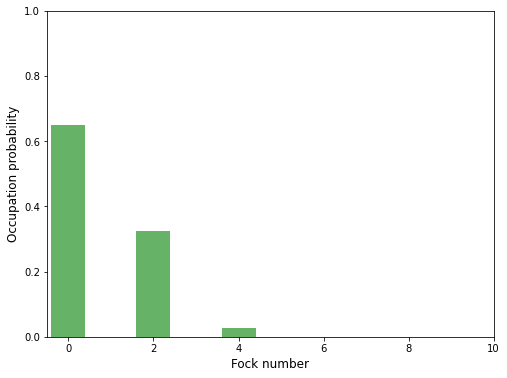

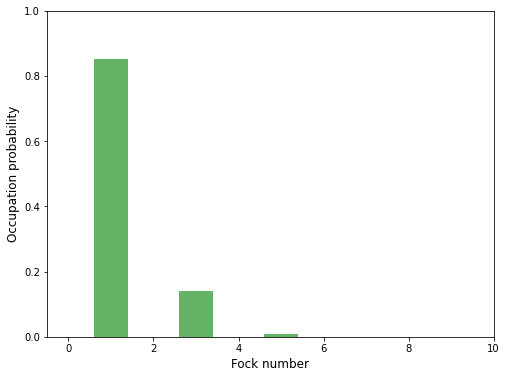

In [17]:
N = 10
logical0, logical1 = two_legged_cat(N, 1)
plot_fock_distribution(logical0)
plot_fock_distribution(logical1)

(<Figure size 576x432 with 1 Axes>,
 <AxesSubplot:xlabel='Fock number', ylabel='Occupation probability'>)

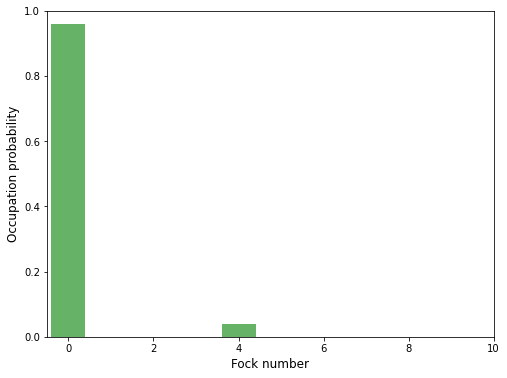

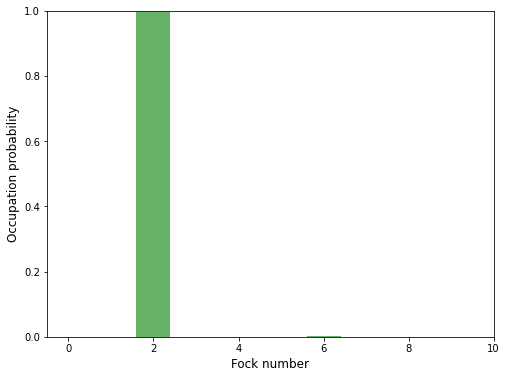

In [18]:
N_max = 10
logical0, logical1 = four_legged_cat(N_max, 1)
plot_fock_distribution(logical0)
plot_fock_distribution(logical1)

(<Figure size 576x432 with 1 Axes>,
 <AxesSubplot:xlabel='Fock number', ylabel='Occupation probability'>)

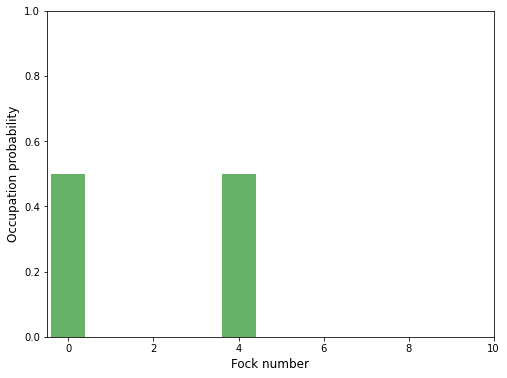

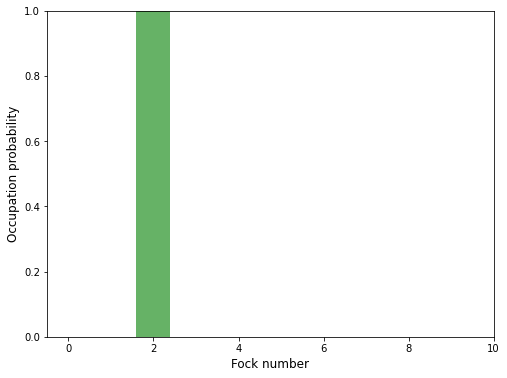

In [19]:
N_max = 10
logical0, logical1 = binomial_ND_22(N_max)
plot_fock_distribution(logical0)
plot_fock_distribution(logical1)

(<Figure size 576x432 with 1 Axes>,
 <AxesSubplot:xlabel='Fock number', ylabel='Occupation probability'>)

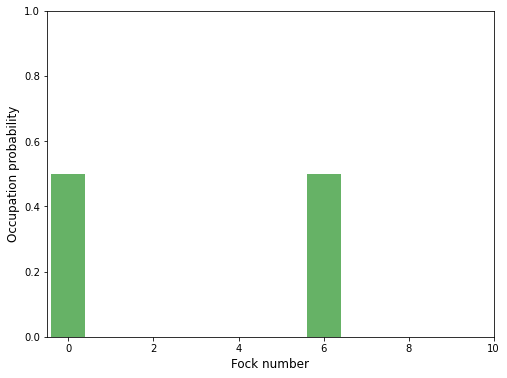

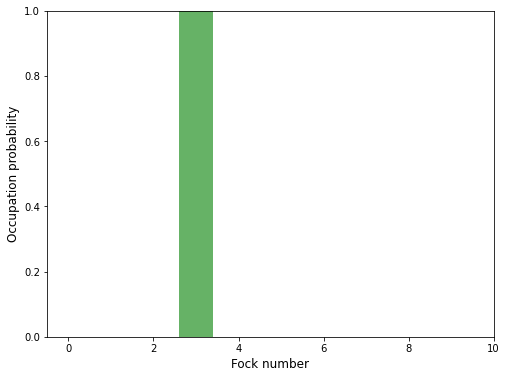

In [20]:
N_max = 10
logical0, logical1 = binomial_ND_31(N_max)
plot_fock_distribution(logical0)
plot_fock_distribution(logical1)

### 2. Gottesman Knill Error Correction Conditions Matrix

In [48]:
def kl_matrix(errors, codewords):
    n = len(errors)
    m = len(codewords)
    kl = np.zeros((n, n, m, m), dtype=complex)
    for a in range(n):
        for b in range(n):
            op = errors[a].dag()*errors[b]
            for i in range(m):
                for j in range(m):
                    kl[a, b, i, j] = (codewords[i].dag()*op*codewords[j]).full()[0, 0]
    return kl

In [87]:
def kl_violation_offdiagonal(kl):
    n, _, d, _ = kl.shape
    total = 0.0
    for a in range(n):
        for b in range(n):
            for mu in range(d):
                for nu in range(d):
                    if mu != nu:
                        total += abs(kl[a, b, mu, nu])**2
    return np.sqrt(total)

In [88]:
def kl_violation_diagonal(kl):
    n, _, d, _ = kl.shape
    total = 0.0
    for a in range(n):
        for b in range(n):
            # average over diagonal code entries
            alpha_ab = np.mean([kl[a, b, mu, mu] for mu in range(d)])
            for mu in range(d):
                total += abs(kl[a, b, mu, mu] - alpha_ab)**2
    return np.sqrt(total)

In [74]:
def plot_kl(kl):
    plt.imshow(np.abs(kl).reshape(kl.shape[0]*kl.shape[1], -1),cmap='gray_r', vmin=0)
    plt.colorbar(label='|KL|')
    plt.show()

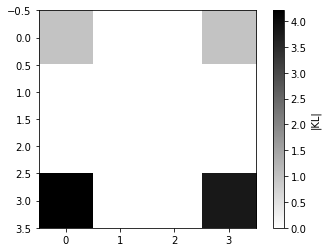

Offdiagonal Violation: 0.0
Diagonal Violation 0.29224814922737874


In [89]:
N_max = 100
logical0, logical1 = four_legged_cat(N_max, 2)
a = destroy(N_max)
id = qeye(N_max)
kl = kl_matrix([id, a], [logical0, logical1])
plot_kl(kl)
print(f"Offdiagonal Violation: {kl_violation_offdiagonal(kl)}")
print(f"Diagonal Violation {kl_violation_diagonal(kl)}")

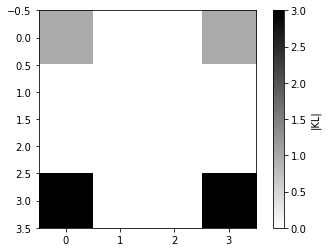

Offdiagonal Violation: 0.0
Diagonal Violation 4.440892098500626e-16


In [91]:
N_max = 100
logical0, logical1 = binomial_ND_024(N_max)
a = destroy(N_max)
id = qeye(N_max)
kl = kl_matrix([id, a], [logical0, logical1])
plot_kl(kl)
print(f"Offdiagonal Violation: {kl_violation_offdiagonal(kl)}")
print(f"Diagonal Violation {kl_violation_diagonal(kl)}")

### 3. Loss-Channel

In [22]:
def loss_kraus_operators(N_max, l_max, eta):
    operators = []
    a = destroy(N_max)
    eta_n_half = Qobj(np.diag(eta ** (np.arange(N_max) / 2)))
    for l in range(l_max+1):
        E = np.sqrt((1-eta)**l/math.factorial(l))*eta_n_half*a**l
        operators.append(E)
    return operators

In [23]:
def recovery_operators(N_max, l_max, logical0, logical1):
    a = destroy(N_max)
    operators = []
    for l in range(l_max):
        w0 = (a**l*logical0).unit()
        w1 = (a**l*logical1).unit()
        R = logical0 * w0.dag() + logical1 * w1.dag()
        operators.append(R)
    return operators

In [24]:
def error_words(N_max, l, logical0, logical1):
    a = destroy(N_max)
    w0 =  a**l*logical0
    w1 = a**l*logical1
    return w0, w1

In [113]:
def avrg_fidelity(A, B):
    r = A/B
    return (r**4 + 4*r**3 - 4*r - 1 + 4*np.log(r)*r**2)/(2*(r-1)*(r+1)**3)

In [147]:
def plot_fidelity(N_max, logical0, logical1, code_name=""):
    F0 = [] # fidelities for no photon loss
    F1 = [] # fidelities for single photon loss

    w00, w01 = error_words(N_max, 0, logical0, logical1)
    w10, w11 = error_words(N_max, 1, logical0, logical1)

    kt_range = np.linspace(0, 0.2, 100)
    for kt in kt_range:
        eta = np.exp(-kt)
        E0, E1 = loss_kraus_operators(N_max, 1, eta)
       
        # Fidelities avaraged over blochsphere
        A0 = (w00.dag() * E0 * logical0).full()[0, 0]
        B0 = (w01.dag() * E0 * logical1).full()[0, 0]
        F0.append(avrg_fidelity(A0, B0))

        A1 = (w10.dag() * E1 * logical0).full()[0, 0]
        B1 = (w11.dag() * E1 * logical1).full()[0, 0]
        F1.append(avrg_fidelity(A1, B1))

    plt.plot(kt_range, F0, label='k=0')
    plt.plot(kt_range, F1, label='k=1')
    plt.title(f"Recovery of {code_name} after photon loss channel")
    plt.xlabel("kt")
    plt.ylabel("Avarage Fidelity")
    plt.legend()  
    plt.tight_layout()
    plt.savefig(
        f"Photon loss channel {code_name}.pdf",
        format="pdf",
        bbox_inches="tight"
    )

<ipython-input-113-c319c44142c9>:2: RuntimeWarning: invalid value encountered in scalar divide
  r = A/B
<ipython-input-113-c319c44142c9>:3: RuntimeWarning: invalid value encountered in scalar divide
  return (r**4 + 4*r**3 - 4*r - 1 + 4*np.log(r)*r**2)/(2*(r-1)*(r+1)**3)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


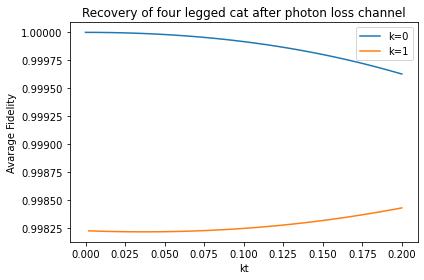

In [148]:
N_max = 100
logical0, logical1 = four_legged_cat(N_max, 2)
plot_fidelity(N_max, logical0, logical1, "four legged cat")

<ipython-input-113-c319c44142c9>:3: RuntimeWarning: invalid value encountered in scalar divide
  return (r**4 + 4*r**3 - 4*r - 1 + 4*np.log(r)*r**2)/(2*(r-1)*(r+1)**3)
<ipython-input-113-c319c44142c9>:2: RuntimeWarning: invalid value encountered in scalar divide
  r = A/B
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


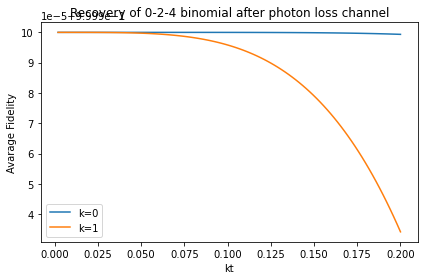

In [149]:
N_max = 10
logical0, logical1 = binomial_ND_024(N_max)
plot_fidelity(N_max, logical0, logical1, "0-2-4 binomial")

<ipython-input-113-c319c44142c9>:2: RuntimeWarning: invalid value encountered in scalar divide
  r = A/B
<ipython-input-113-c319c44142c9>:3: RuntimeWarning: invalid value encountered in scalar divide
  return (r**4 + 4*r**3 - 4*r - 1 + 4*np.log(r)*r**2)/(2*(r-1)*(r+1)**3)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


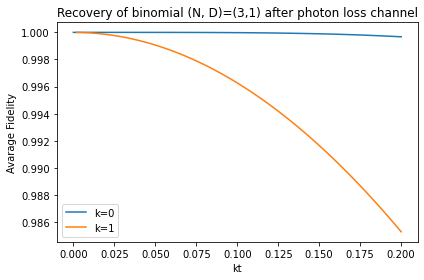

In [150]:
N_max = 10
logical0, logical1 = binomial_ND_31(N_max)
plot_fidelity(N_max, logical0, logical1, "binomial (N, D)=(3,1)")

<ipython-input-113-c319c44142c9>:2: RuntimeWarning: invalid value encountered in scalar divide
  r = A/B
<ipython-input-113-c319c44142c9>:3: RuntimeWarning: invalid value encountered in scalar divide
  return (r**4 + 4*r**3 - 4*r - 1 + 4*np.log(r)*r**2)/(2*(r-1)*(r+1)**3)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


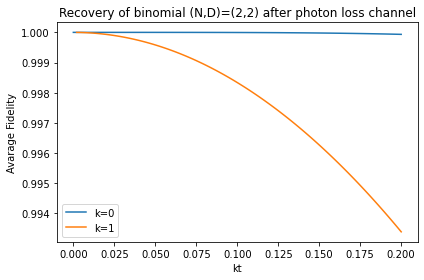

In [151]:
N_max = 100
logical0, logical1 = binomial_ND_22(N_max)
plot_fidelity(N_max, logical0, logical1, "binomial (N,D)=(2,2)")

### 4. Pure-Dephasing-Channel

In [152]:
def dephasing_kraus_operators(N_max, l_max, lam):
    operators = []
    n = num(N_max)
    exp_n_squared = Qobj(np.diag(np.exp(-0.5*lam*np.arange(N_max)**2)))
    for l in range(l_max+1):
        E = np.sqrt((lam)**l/math.factorial(l))*exp_n_squared*n**l
        operators.append(E)
    return operators

In [168]:
def plot_fidelity_after_dephasing(N_max, logical0, logical1, code_name=""):
    F0 = [] 
    F1 = [] 

    kt_range = np.linspace(0, 0.2, 100)
    for kt in kt_range:
        E0, E1 = dephasing_kraus_operators(N_max, 1, kt)
       
        # Fidelities avaraged over blochsphere
        A0 = (logical0.dag() * E0 * logical0).full()[0, 0]
        B0 = (logical1.dag() * E0 * logical1).full()[0, 0]
        F0.append(avrg_fidelity(A0, B0))

        A1 = (logical0.dag() * E1 * logical0).full()[0, 0]
        B1 = (logical1.dag() * E1 * logical1).full()[0, 0]
        F1.append(avrg_fidelity(A1, B1))

    plt.plot(kt_range, F0, label='k=0')
    plt.plot(kt_range, F1, label='k=1')
    plt.title(f"Recovery of {code_name} after dephansing channel")
    plt.xlabel("kt")
    plt.ylabel("Avarage Fidelity")
    plt.legend()  
    plt.tight_layout()
    plt.savefig(
        f"Dephasing channel {code_name}.pdf",
        format="pdf",
        bbox_inches="tight"
    )

<ipython-input-113-c319c44142c9>:2: RuntimeWarning: invalid value encountered in scalar divide
  r = A/B
<ipython-input-113-c319c44142c9>:3: RuntimeWarning: invalid value encountered in scalar divide
  return (r**4 + 4*r**3 - 4*r - 1 + 4*np.log(r)*r**2)/(2*(r-1)*(r+1)**3)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


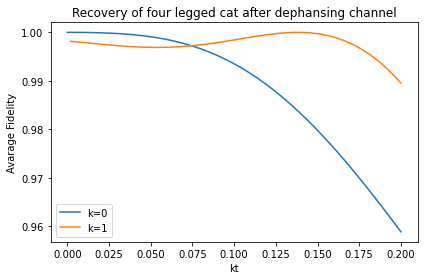

In [169]:
N_max = 100
logical0, logical1 = four_legged_cat(N_max, alpha=2)
plot_fidelity_after_dephasing(N_max, logical0, logical1, "four legged cat")

<ipython-input-113-c319c44142c9>:3: RuntimeWarning: invalid value encountered in scalar divide
  return (r**4 + 4*r**3 - 4*r - 1 + 4*np.log(r)*r**2)/(2*(r-1)*(r+1)**3)
<ipython-input-113-c319c44142c9>:2: RuntimeWarning: invalid value encountered in scalar divide
  r = A/B
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


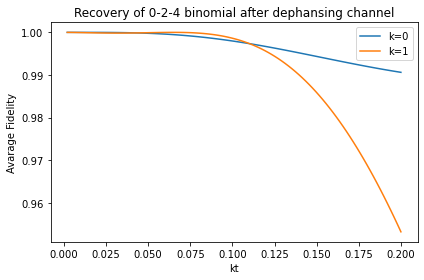

In [155]:
N_max = 100
logical0, logical1 = binomial_ND_024(N_max)
plot_fidelity_after_dephasing(N_max, logical0, logical1, "0-2-4 binomial")

<ipython-input-113-c319c44142c9>:2: RuntimeWarning: invalid value encountered in scalar divide
  r = A/B
<ipython-input-113-c319c44142c9>:3: RuntimeWarning: invalid value encountered in scalar divide
  return (r**4 + 4*r**3 - 4*r - 1 + 4*np.log(r)*r**2)/(2*(r-1)*(r+1)**3)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


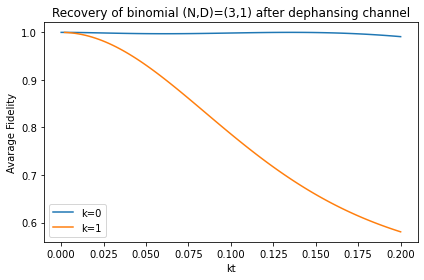

In [156]:
N_max = 100
logical0, logical1 = binomial_ND_31(N_max)
plot_fidelity_after_dephasing(N_max, logical0, logical1, "binomial (N,D)=(3,1)")

<ipython-input-113-c319c44142c9>:2: RuntimeWarning: invalid value encountered in scalar divide
  r = A/B
<ipython-input-113-c319c44142c9>:3: RuntimeWarning: invalid value encountered in scalar divide
  return (r**4 + 4*r**3 - 4*r - 1 + 4*np.log(r)*r**2)/(2*(r-1)*(r+1)**3)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


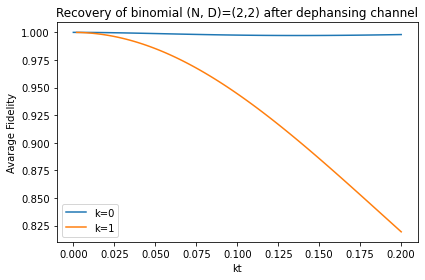

In [157]:
N_max = 100
logical0, logical1 = binomial_ND_22(N_max)
plot_fidelity_after_dephasing(N_max, logical0, logical1, "binomial (N, D)=(2,2)")

### 5. Cat fidelity for non expanded Photon loss

In [191]:
def binomial_ND_12(N_max):
    # mean number 3/2
    logical0 = 0.5*(fock(N_max, 0) + np.sqrt(3)*fock(N_max, 4))
    logical1 = 0.5*(np.sqrt(3)*fock(N_max, 1) + fock(N_max, 3))
    return logical0, logical1

In [192]:
def binomial_ND_14(N_max):
    # mean number 5/2
    logical0 = 0.25*(fock(N_max, 0) + np.sqrt(2)*fock(N_max, 2) + np.sqrt(5)*fock(N_max, 4))
    logical1 = 0.25*(np.sqrt(3)*fock(N_max, 1) + np.sqrt(10)*fock(N_max, 3) + fock(N_max, 5))
    return logical0, logical1

In [193]:
def binomial_ND_31(N_max):
    # mean number 3
    logical0 = 0.5*(fock(N_max, 0) + fock(N_max, 6))
    logical1 = fock(N_max, 3)
    return logical0, logical1

In [224]:
def binomial_ND(N_max, N, D):
    logical0 = 0 * fock(N_max, 0)
    logical1 = 0 * fock(N_max, 0)
    for m in range(D + 2): # m = 0, 1, ..., D+1
        n_photons = m * N
        if n_photons >= N_max:
            raise ValueError(f"N_max must be greater than {n_photons}.")
        amplitude = np.sqrt(comb(D + 1, m)) / (2 ** (D / 2))
        if m % 2 == 0:
            logical0 += amplitude * fock(N_max, n_photons)
        else:
            logical1 += amplitude * fock(N_max, n_photons)
    return logical0.unit(), logical1.unit()

In [239]:
def calculate_recoverey_fidelity_E1(N_max, logical0, logical1, eta):
    w00, w01 = error_words(N_max, 0, logical0, logical1)
    w10, w11 = error_words(N_max, 1, logical0, logical1)
    E0, E1 = loss_kraus_operators(N_max, 1, eta)
    A0 = (w00.dag() * E0 * logical0).full()[0, 0]
    B0 = (w01.dag() * E0 * logical1).full()[0, 0]
    F0 = avrg_fidelity(A0, B0)

    A1 = (w10.dag() * E1 * logical0).full()[0, 0]
    B1 = (w11.dag() * E1 * logical1).full()[0, 0]
    F1 = avrg_fidelity(A1, B1)
    
    return F0, F1

In [242]:
def plot_fidelities_for_variang_alpha(N_max, kt):
    eta = np.exp(-kt)
    E0, E1 = loss_kraus_operators(N_max, 1, eta)
    F0 = [] # fidelities for no photon loss
    F1 = [] # fidelities for single photon loss

    alpha_range = np.linspace(1, 3, 100)
    for alpha in alpha_range:
        
        logical0, logical1 = four_legged_cat(N_max, alpha)
        w00, w01 = error_words(N_max, 0, logical0, logical1)
        w10, w11 = error_words(N_max, 1, logical0, logical1)

        #Fidelities avaraged over blochsphere
        A0 = (w00.dag() * E0 * logical0).full()[0, 0]
        B0 = (w01.dag() * E0 * logical1).full()[0, 0]
        F0.append(avrg_fidelity(A0, B0))

        A1 = (w10.dag() * E1 * logical0).full()[0, 0]
        B1 = (w11.dag() * E1 * logical1).full()[0, 0]
        F1.append(avrg_fidelity(A1, B1))


    """
     # fidelities of recovered binomial codes
    binomial_code_fidelities = []
    binomial_code_mean_numbers = [3/2, 2, 5/2, 3]

    # bin 1,2 n=3/2
    logical0, logical1 = binomial_ND_12(N_max)
    binomial_code_fidelities.append(calculate_recoverey_fidelity_E1(N_max, logical0, logical1, eta))

    # bin 0-2-4 n=2
    logical0, logical1 = binomial_ND_024(N_max)
    binomial_code_fidelities.append(calculate_recoverey_fidelity_E1(N_max, logical0, logical1, eta))
    
    # bin 1,4 n=5/2
    logical0, logical1 = binomial_ND_14(N_max)
    binomial_code_fidelities.append(calculate_recoverey_fidelity_E1(N_max, logical0, logical1, eta))

    # bin 3,1 n=3
    logical0, logical1 = binomial_ND_31(N_max)
    binomial_code_fidelities.append(calculate_recoverey_fidelity_E1(N_max, logical0, logical1, eta))
    """
   

    binomial_code_fidelities_0 = []
    binomial_code_fidelities_1 = []
    binomial_code_mean_numbers = []

    binomial_parameters = [
        (1, 1),   # mean_n = 1*(1+1)/2 = 1
        (1, 2),   # mean_n = 1.5
        (1, 3),   # mean_n = 2
        (1, 4),   # mean_n = 2.5
        (1, 5),   # mean_n = 3
        (2, 1),   # mean_n = 2*(1+1)/2 = 2  (only m=0,1,2; comb(2,m))
        (2, 2),   # mean_n = 3
        (2, 3),   # mean_n = 4
        (2, 4),   # mean_n = 5
        (3, 2),   # mean_n = 3*(2+1)/2 = 4.5  (m up to 3; comb(3,m))
        (3, 3),   # mean_n = 6
        (4, 3),   # mean_n = 4*(3+1)/2 = 8  (m up to 4; comb(4,m))
    ]

    for (N, D) in binomial_parameters:
        logical0, logical1 = binomial_ND(N_max, N, D)
        mean_n = N * (D + 1) / 2
        F0, F1 = calculate_recoverey_fidelity_E1(
            N_max, logical0, logical1, eta
        )
        binomial_code_mean_numbers.append(mean_n)
        binomial_code_fidelities_0.append(F0)
        binomial_code_fidelities_1.append(F1)
        

    F1 = np.array(F1)
    binomial_code_fidelities_0 = np.array(binomial_code_fidelities_0)
    binomial_x = np.sqrt(np.array(binomial_code_mean_numbers))

    # Top -Fidelity
    plt.plot(alpha_range, F1, label='Four-legged cat E1')
    plt.plot(alpha_range, F0, label='Four-legged cat E0')
    plt.scatter(
        binomial_x,
        binomial_code_fidelities_0,
        label='Binomial codes E0',
        marker='o',
        s=55,
        zorder=3
    )
    plt.scatter(
        binomial_x,
        binomial_code_fidelities_1,
        label='Binomial codes E1',
        marker='o',
        s=55,
        zorder=3
    )

    plt.set_ylim(0.9, 1.001)  
    plt.set_ylabel('F')
    plt.set_title('Recovery after photon loss channel')
    plt.legend()
    plt.grid(True, alpha=0.3)


    """"
    # Bottom  1 - Fidelity
    ax2.plot(alpha_range, 1 - F0, label='Four-legged cat E0')
    ax2.plot(alpha_range, 1 - F1, label='Four-legged cat E1')
    ax2.scatter(
        binomial_x,
        1 - binomial_code_fidelities,
        label='Binomial codes',
        marker='o',
        s=55,
        zorder=3
    )

    ax2.set_yscale('log')
    ax2.set_xlabel("alpha")
    ax2.set_ylabel("1 - F")
    ax2.legend()
    ax2.grid(True, alpha=0.3, which='both')

    plt.tight_layout()
    plt.savefig(
        "Four-legged-cat-recovery-comparison.pdf",
        format="pdf",
        bbox_inches="tight"
    )
    """
    plt.show()

In [244]:
def plot_fidelities_for_variang_alpha(N_max, kt):
    eta = np.exp(-kt)
    E0, E1 = loss_kraus_operators(N_max, 1, eta)
    F0 = [] # fidelities for no photon loss
    F1 = [] # fidelities for single photon loss

    alpha_range = np.linspace(1, 3, 100)
    for alpha in alpha_range:
        
        logical0, logical1 = four_legged_cat(N_max, alpha)
        w00, w01 = error_words(N_max, 0, logical0, logical1)
        w10, w11 = error_words(N_max, 1, logical0, logical1)

        #Fidelities avaraged over blochsphere
        A0 = (w00.dag() * E0 * logical0).full()[0, 0]
        B0 = (w01.dag() * E0 * logical1).full()[0, 0]
        F0.append(avrg_fidelity(A0, B0))

        A1 = (w10.dag() * E1 * logical0).full()[0, 0]
        B1 = (w11.dag() * E1 * logical1).full()[0, 0]
        F1.append(avrg_fidelity(A1, B1))

    binomial_code_fidelities_0 = []
    binomial_code_fidelities_1 = []
    binomial_code_mean_numbers = []

    binomial_parameters = [
        (1, 1),
        (1, 2),
        (1, 3),
        (1, 4),
        (1, 5),
        (2, 1),
        (2, 2),
        (2, 3),
        (2, 4),
        (3, 2),
        (3, 3),
        (4, 3),
    ]

    for (N, D) in binomial_parameters:
        logical0, logical1 = binomial_ND(N_max, N, D)

        mean_n = N * (D + 1) / 2

        F_bin0, F_bin1 = calculate_recoverey_fidelity_E1(
            N_max, logical0, logical1, eta
        )

        binomial_code_mean_numbers.append(mean_n)
        binomial_code_fidelities_0.append(F_bin0)
        binomial_code_fidelities_1.append(F_bin1)

    binomial_code_fidelities_0 = np.array(binomial_code_fidelities_0)
    binomial_code_fidelities_1 = np.array(binomial_code_fidelities_1)

    binomial_x = np.sqrt(np.array(binomial_code_mean_numbers))

    # Plot fidelities
    plt.figure(figsize=(9, 6))

    plt.plot(alpha_range, F0, label='Four-legged cat E0')
    plt.plot(alpha_range, F1, label='Four-legged cat E1')

    plt.scatter(
        binomial_x,
        binomial_code_fidelities_0,
        label='Binomial codes E0',
        marker='o',
        s=55,
        zorder=3
    )

    plt.scatter(
        binomial_x,
        binomial_code_fidelities_1,
        label='Binomial codes E1',
        marker='s',
        s=55,
        zorder=3
    )

    plt.ylim(0.9, 1.001)
    plt.xlabel(r'$\alpha$ or $\sqrt{\langle n\rangle}$')
    plt.ylabel('Fidelity')
    plt.title('Recovery after photon loss channel')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1289: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/Users/leorobinson/opt/anaconda3/lib/python3.8/site-packages/matplotlib/collections.py:202: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


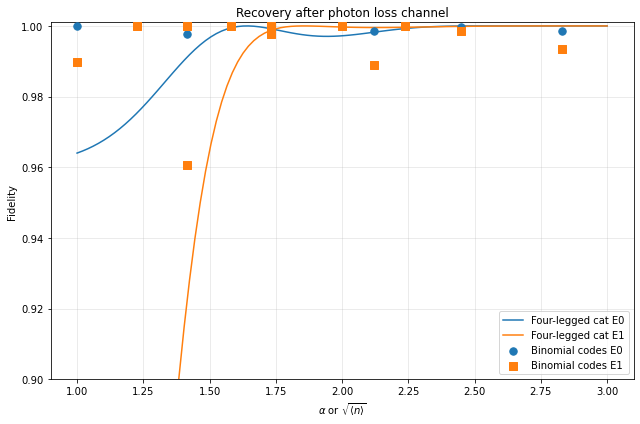

In [247]:
N_max = 100
kt = 0.5
plot_fidelities_for_variang_alpha(N_max, kt)